# Exploration du jeu de données

Ce notebook charge les images satellites Sentinel-2 (déjà séparées en train/test)
et explore leur structure : nombre d'échantillons, dimensions, et surtout la
distribution des classes de cultures agricoles, qui est fortement déséquilibrée.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
CLASSES_NAMES = [
    "Avoine d'hiver",
    "Avoine de printemps",
    "Blé tendre d'hiver",
    "Blé tendre de printemps",
    "Colza d'hiver",
    "Luzerne déshydratée",
    "Luzerne",
    "Mélange de légumineuses et graminées",
    "Maïs",
    "Maïs ensilage",
    "Orge d'hiver",
    "Orge de printemps",
    "Prairie permanente - herbe",
    "Prairie permanente - ressources fourragères ligneuses",
    "Prairie en rotation longue",
    "Pomme de terre de consommation",
    "Prairie temporaire",
    "Soja",
    "Tournesol",
    "Triticale d'hiver",
]
MONTHS = ['Fev', 'Mar', 'Avr', 'Mai', 'Jun', 'Jul', 'Aou', 'Sep', 'Oct', 'Nov']

## Chargement des données

Les images (`train_images.npy`, `test_public_images.npy`) sont volumineuses
(respectivement ~586 Mo et ~147 Mo) et ne sont pas incluses dans ce dépôt
(voir `data/NOTE_DONNEES.md`). Seules les étiquettes sont fournies ici ; ce
notebook charge les images si elles sont présentes localement, sinon il se
limite à l'analyse des étiquettes.

In [3]:
DATA_DIR = Path("data")

Y_train = np.load(DATA_DIR / "train_labels.npy")
Y_test = np.load(DATA_DIR / "test_public_labels.npy")

images_path = DATA_DIR / "train_images.npy"
if images_path.exists():
    X_train = np.load(images_path).astype(np.float32)
    X_test = np.load(DATA_DIR / "test_public_images.npy").astype(np.float32)
    print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
else:
    X_train = X_test = None
    print("Images non présentes localement (voir data/NOTE_DONNEES.md) : "
          "analyse limitée aux étiquettes.")

print(f"Y_train: {Y_train.shape}, Y_test: {Y_test.shape}")

Images non présentes localement (voir data/NOTE_DONNEES.md) : analyse limitée aux étiquettes.
Y_train: (10000,), Y_test: (2500,)


## Distribution des classes

Chaque échantillon appartient à l'une des 20 cultures agricoles listées
ci-dessus. On compte le nombre d'exemples par classe dans les jeux
d'entraînement et de test.

In [4]:
counts_train = np.bincount(Y_train, minlength=len(CLASSES_NAMES))
counts_test = np.bincount(Y_test, minlength=len(CLASSES_NAMES))

classes_df = pd.DataFrame({
    "classe": CLASSES_NAMES,
    "n_train": counts_train,
    "n_test": counts_test,
    "freq_train": counts_train / counts_train.sum(),
    "freq_test": counts_test / counts_test.sum(),
})
classes_df.sort_values("n_train", ascending=False)

,classe,n_train,n_test,freq_train,freq_test
2,Blé tendre d'hiver,2464,781,0.2464,0.3124
12,Prairie permanente - herbe,2088,266,0.2088,0.1064
10,Orge d'hiver,914,265,0.0914,0.1060
7,Mélange de légumineuses et graminées,757,84,0.0757,0.0336
4,Colza d'hiver,727,225,0.0727,0.0900
11,Orge de printemps,598,235,0.0598,0.0940
8,Maïs,595,116,0.0595,0.0464
18,Tournesol,454,120,0.0454,0.0480
3,Blé tendre de printemps,272,108,0.0272,0.0432
6,Luzerne,267,36,0.0267,0.0144


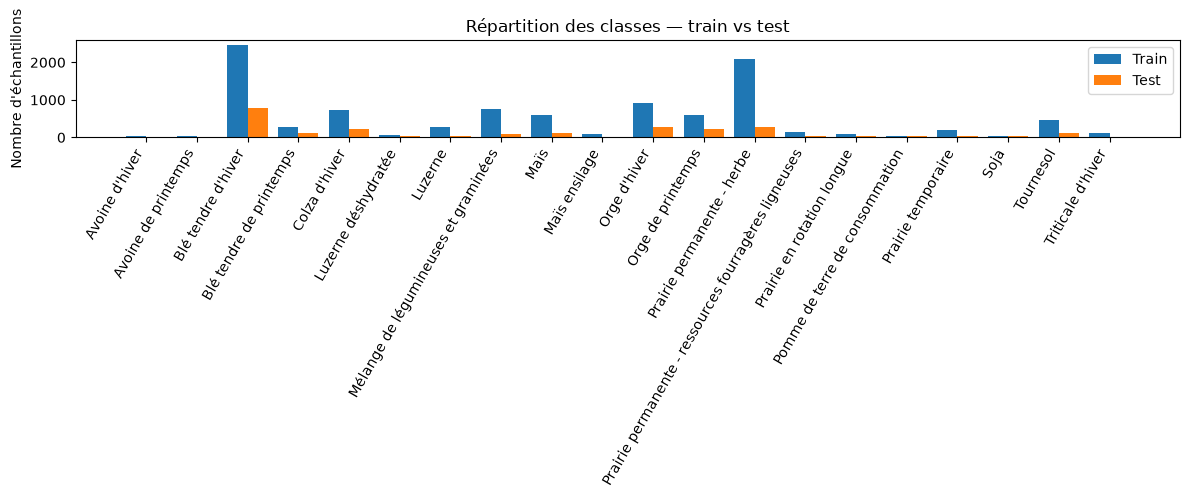

In [5]:
x = np.arange(len(CLASSES_NAMES))
plt.figure(figsize=(12, 5))
plt.bar(x - 0.2, counts_train, width=0.4, label="Train")
plt.bar(x + 0.2, counts_test, width=0.4, label="Test")
plt.xticks(x, CLASSES_NAMES, rotation=60, ha="right")
plt.ylabel("Nombre d'échantillons")
plt.title("Répartition des classes — train vs test")
plt.legend()
plt.tight_layout()
plt.show()

**Observation.** Certaines classes (ex. Blé tendre d'hiver, Prairie permanente -
herbe) comptent plusieurs milliers d'exemples, tandis que d'autres (ex. Avoine
de printemps, Soja) n'en comptent qu'une poignée. Ce déséquilibre motive le
choix de métriques adaptées (balanced accuracy, F1 macro) et l'exploration de
stratégies de rééchantillonnage (voir `02_pretraitement_reechantillonnage.ipynb`).

## Aperçu visuel d'un échantillon

Chaque champ est décrit par une séquence de 10 images mensuelles (février à
novembre), sur 3 canaux spectraux (proche infrarouge, rouge, vert). Cette
cellule affiche la séquence complète d'un échantillon si les images sont
disponibles localement.

In [6]:
def display_sample(X, Y, idx, classes_names=CLASSES_NAMES, months=MONTHS):
    """Affiche la séquence des 10 images mensuelles d'un échantillon."""
    img = X[idx].transpose(0, 2, 3, 1).copy()  # (mois, H, W, canaux)
    for c in range(img.shape[-1]):
        chan = img[..., c]
        img[..., c] = (chan - chan.min()) / (chan.max() - chan.min() + 1e-8)
    img = img.clip(0, 1)

    fig, axes = plt.subplots(1, img.shape[0], figsize=(2 * img.shape[0], 2.5))
    for m in range(img.shape[0]):
        axes[m].imshow(img[m])
        axes[m].set_title(months[m])
        axes[m].axis("off")
    fig.suptitle(f"Échantillon {idx} — classe : {classes_names[Y[idx]]}")
    plt.tight_layout()
    plt.show()


if X_train is not None:
    display_sample(X_train, Y_train, idx=0)
else:
    print("Images non disponibles localement : cellule non exécutable.")

Images non disponibles localement : cellule non exécutable.
